# Course of Action Simulation

This project demonstrates a fictional decision-support model for comparing three possible routes under uncertainty. It combines deterministic modelling, Monte Carlo simulation, multi-criteria decision analysis, and sensitivity analysis.

All routes, parameters, probabilities, and decision thresholds are fictional and are used solely to demonstrate statistical and programming techniques.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Scenario Parameters

Three fictional routes (Alpha, Bravo, and Charlie) are represented by distance, terrain difficulty, predicted threat probability, weather, equipment reliability, available supplies, and confidence in the threat estimate.

In [4]:
routes = {
    'Alpha': {
        'route_length': 20,
        'terrain_difficulty': 0.3,
        'threat_probability': 0.50,
        'weather_severity': 0.2,
        'equipment_reliability': 0.90,
        'supply_level': 100,
        'intel_confidence': 0.80
    },
    'Bravo': {
        'route_length': 35,
        'terrain_difficulty': 0.5,
        'threat_probability': 0.15,
        'weather_severity': 0.2,
        'equipment_reliability': 0.90,
        'supply_level': 100,
        'intel_confidence': 0.9
    },
    'Charlie': {
        'route_length': 27,
        'terrain_difficulty': 0.4,
        'threat_probability': 0.30,
        'weather_severity': 0.2,
        'equipment_reliability': 0.90,
        'supply_level': 100,
        'intel_confidence': 0.5        
    }
}

## Deterministic Baseline

Before introducing uncertainty, each route is evaluated using deterministic estimates of travel time, resource consumption, threat exposure, and feasibility.

Travel speed is reduced by terrain difficulty and weather severity, while resource consumption increases with route length and terrain difficulty. A route is considered feasible when its estimated resource consumption does not exceed its available supply.

Threat estimates are adjusted upward when intelligence confidence is lower. This baseline provides the reference values used later in the Monte Carlo simulation.

In [6]:
base_speed = 10
base_consumption_rate = 2
uncertainty_penalty = 0.25

results = {}

for route_name, route_data in routes.items():
    route_length = route_data['route_length']
    terrain_difficulty = route_data['terrain_difficulty']
    weather_severity = route_data['weather_severity']
    supply_level = route_data['supply_level']
    threat_probability = route_data['threat_probability']
    intel_confidence = route_data['intel_confidence']

    effective_speed = base_speed * (1 - terrain_difficulty) * (1 - weather_severity)
    travel_time = route_length / effective_speed
    resources_consumed = route_length * base_consumption_rate * (1 + terrain_difficulty)
    feasible = resources_consumed <= supply_level
    adjusted_threat = min(
        threat_probability + (1 - intel_confidence) * uncertainty_penalty,
        1
    )
    
    results[route_name] = {
        'travel_time': travel_time,
        'resources_consumed': resources_consumed,
        'adjusted_threat': adjusted_threat,
        'feasible': feasible
    }

for name, data in results.items():
    print(f'{name}')
    print(f'    Travel time: {data['travel_time']:.2f} hours')
    print(f'    Resources consumed: {data['resources_consumed']:.2f}')
    print(f'    Adjusted threat: {data['adjusted_threat']:.3f}')
    print(f'    Feasible: {data['feasible']}')
    print()

Alpha
    Travel time: 3.57 hours
    Resources consumed: 52.00
    Adjusted threat: 0.550
    Feasible: True

Bravo
    Travel time: 8.75 hours
    Resources consumed: 105.00
    Adjusted threat: 0.175
    Feasible: False

Charlie
    Travel time: 5.62 hours
    Resources consumed: 75.60
    Adjusted threat: 0.425
    Feasible: True



## Modelling Uncertainty

The deterministic baseline assumes that route conditions are known with certainty. To represent uncertainty, the simulation introduces stochastic threat and equipment events.

Threat probability is modelled using a Beta distribution. The predicted threat probability determines the mean of the distribution, while intelligence confidence controls its concentration. Higher confidence produces a narrower distribution around the predicted probability, while lower confidence produces greater uncertainty.

Equipment reliability is adjusted for terrain and weather conditions. Equipment failures and threat encounters can add travel time and resource consumption to an individual simulation.

In [8]:
def simulate_route(route_data, baseline_travel_time, baseline_resources, rng):
    '''
    Simulate one outcome for a route under uncertain threat and equipment conditions.

    Returns simulated travel time, resource consumption, event outcomes, and mission success.
    '''
    equipment_reliability = route_data['equipment_reliability']
    terrain_difficulty = route_data['terrain_difficulty']
    weather_severity = route_data['weather_severity']
    terrain_equipment_effect = 0.25
    weather_equipment_effect = 0.20

    # Adjust equipment reliability for terrain and weather
    effective_equipment_reliability = (
        equipment_reliability
        * (1 - terrain_equipment_effect * terrain_difficulty)
        * (1 - weather_equipment_effect * weather_severity)
    )

    # Determine whether equipment failure occurs
    equipment_random_number = rng.random()
    equipment_failure = equipment_random_number > effective_equipment_reliability
    
    if equipment_failure:
        equipment_additional_time = rng.uniform(0.5, 2.0)
        equipment_additional_resources = rng.uniform(5, 15)
    else:
        equipment_additional_time = 0
        equipment_additional_resources = 0

    #Model uncertainty in the predicted threat probability
    predicted_threat_probability = route_data['threat_probability']
    intel_confidence = route_data['intel_confidence']
    k_min = 5
    k_max = 100
    k = k_min + intel_confidence * (k_max - k_min)
    alpha = predicted_threat_probability * k
    beta = (1 - predicted_threat_probability) * k
    simulated_threat_probability = rng.beta(alpha, beta)

    # Determine whether a threat encounter occurs
    threat_random_number = rng.random()
    threat_occurs = threat_random_number < simulated_threat_probability
    
    if threat_occurs:
        threat_additional_time = rng.uniform(0.5, 3.0)
        threat_additional_resources = rng.uniform(10, 25)
    else:
        threat_additional_time = 0
        threat_additional_resources = 0

    # Calculate the final simulated outcome
    simulated_travel_time = (
        baseline_travel_time
        + equipment_additional_time
        + threat_additional_time
    )
    simulated_resources_consumed = (
        baseline_resources
        + equipment_additional_resources
        + threat_additional_resources
    )

    supply_level = route_data['supply_level']
    mission_success = simulated_resources_consumed <= supply_level
    
    return {
        'effective_equipment_reliability': effective_equipment_reliability,
        'equipment_failure': equipment_failure,
        'equipment_additional_time': equipment_additional_time,
        'equipment_additional_resources': equipment_additional_resources,
        'simulated_threat_probability': simulated_threat_probability,
        'threat_occurs': threat_occurs,
        'threat_additional_time': threat_additional_time,
        'threat_additional_resources': threat_additional_resources,
        'simulated_travel_time': simulated_travel_time,
        'simulated_resources_consumed': simulated_resources_consumed,
        'mission_success': mission_success
    }


## Monte Carlo Simulation

Each route is simulated 10,000 times to estimate its performance under uncertain equipment and threat conditions.

For each simulation, the model records mission success, equipment failure, threat encounters, travel time, and resource consumption. The resulting distributions are used to compare the routes beyond their deterministic baseline estimates.

In [10]:
rng = np.random.default_rng(42)
num_simulations = 10000
simulation_results = {}

for name, route_data in routes.items():

    success_count = 0
    equipment_failure_count = 0
    threat_count = 0
    total_travel_time = 0
    total_resources_consumed = 0
    
    travel_times = []
    resources_consumed = []

    baseline_travel_time = results[name]['travel_time']
    baseline_resources = results[name]['resources_consumed']

    for _ in range(num_simulations):

        outcome = simulate_route(
            route_data,
            baseline_travel_time,
            baseline_resources,
            rng
        )

        total_travel_time += outcome['simulated_travel_time']
        total_resources_consumed += outcome['simulated_resources_consumed']

        travel_times.append(outcome['simulated_travel_time'])
        resources_consumed.append(outcome['simulated_resources_consumed'])

        if outcome['mission_success']:
            success_count += 1

        if outcome['equipment_failure']:
            equipment_failure_count += 1

        if outcome['threat_occurs']:
            threat_count += 1

    simulation_results[name] = {
        'success_count': success_count,
        'equipment_failure_count': equipment_failure_count,
        'threat_count': threat_count,
        'total_travel_time': total_travel_time,
        'total_resources_consumed': total_resources_consumed,
        'travel_times': travel_times,
        'resources_consumed': resources_consumed
    }

## Simulation Results

The following results summarize the outcomes of 10,000 simulations for each route.

Mission success is defined as completing a route without exceeding the available supply. Equipment failures and threat encounters may increase travel time and resource consumption.

The reported success rates are estimates based on the simulation assumptions, not guarantees of real-world outcomes.

In [12]:
for name, data in simulation_results.items():
    success_rate = data['success_count'] / num_simulations
    equipment_failure_rate = data['equipment_failure_count'] / num_simulations
    threat_rate = data['threat_count'] / num_simulations
    average_travel_time = data['total_travel_time'] / num_simulations
    average_resources = data['total_resources_consumed'] / num_simulations
    print(name)
    print(f'    Mission success rate: {success_rate:.2%}')
    print(f'    Equipment failure rate: {equipment_failure_rate:.2%}')
    print(f'    Threat encounter rate: {threat_rate:.2%}')
    print(f'    Average travel time: {average_travel_time:.2f} hours')
    print(f'    Average resources consumed: {average_resources:.2f}')

Alpha
    Mission success rate: 100.00%
    Equipment failure rate: 19.90%
    Threat encounter rate: 50.12%
    Average travel time: 4.70 hours
    Average resources consumed: 62.76
Bravo
    Mission success rate: 0.00%
    Equipment failure rate: 24.96%
    Threat encounter rate: 15.21%
    Average travel time: 9.32 hours
    Average resources consumed: 110.15
Charlie
    Mission success rate: 94.19%
    Equipment failure rate: 21.87%
    Threat encounter rate: 30.45%
    Average travel time: 6.43 hours
    Average resources consumed: 83.13


## Distribution Analysis

Average values provide a useful summary of each route, but they do not describe the full range of possible outcomes.

To better understand variability, the simulated travel times and resource consumption are examined using percentiles and histograms.

The 90th and 95th percentiles help identify less favourable outcomes, while resource consumption histograms show how frequently simulated outcomes approach or exceed the available supply.

In [14]:
for name, data in simulation_results.items():

    travel_times = data['travel_times']
    resources_consumed = data['resources_consumed']

    median_travel_time = np.percentile(travel_times, 50)
    p90_travel_time = np.percentile(travel_times, 90)
    p95_travel_time = np.percentile(travel_times, 95)

    median_resources_consumed = np.percentile(resources_consumed, 50)
    p90_resources_consumed = np.percentile(resources_consumed, 90)
    p95_resources_consumed = np.percentile(resources_consumed, 95)

    print(name)
    print('    Travel Time (hours):')
    print(f'        Median: {median_travel_time:.2f}')
    print(f'        90th Percentile: {p90_travel_time:.2f}')
    print(f'        95th Percentile: {p95_travel_time:.2f}')
    print('    Resources Consumed (units):')
    print(f'        Median: {median_resources_consumed:.2f}')
    print(f'        90th Percentile: {p90_resources_consumed:.2f}')
    print(f'        95th Percentile: {p95_resources_consumed:.2f}')

Alpha
    Travel Time (hours):
        Median: 4.49
        90th Percentile: 6.34
        95th Percentile: 6.64
    Resources Consumed (units):
        Median: 63.33
        90th Percentile: 76.09
        95th Percentile: 79.99
Bravo
    Travel Time (hours):
        Median: 8.75
        90th Percentile: 10.64
        95th Percentile: 11.23
    Resources Consumed (units):
        Median: 105.00
        90th Percentile: 121.96
        95th Percentile: 127.47
Charlie
    Travel Time (hours):
        Median: 5.62
        90th Percentile: 8.07
        95th Percentile: 8.49
    Resources Consumed (units):
        Median: 75.60
        90th Percentile: 97.57
        95th Percentile: 100.41


### Resource Consumption Distributions

Histograms are used to visualize the distribution of resource consumption across simulated outcomes.

The dashed vertical line represents each route's available supply. Outcomes to the right of this line exceed the supply limit and are classified as unsuccessful.

These plots help illustrate why some routes have higher failure rates despite having acceptable average resource consumption.

In [16]:
def plot_resource_distribution(resources, route_name, supply_limit):
    plt.figure(figsize=(8,5))
    plt.hist(resources, bins=30)
    plt.xlabel('Resources Consumed')
    plt.ylabel('Number of Simulations')
    plt.title(f'{route_name} - Simulated Resource Consumption')
    plt.axvline(supply_limit, linestyle='--', label='Supply Limit')
    plt.legend()
    plt.show()

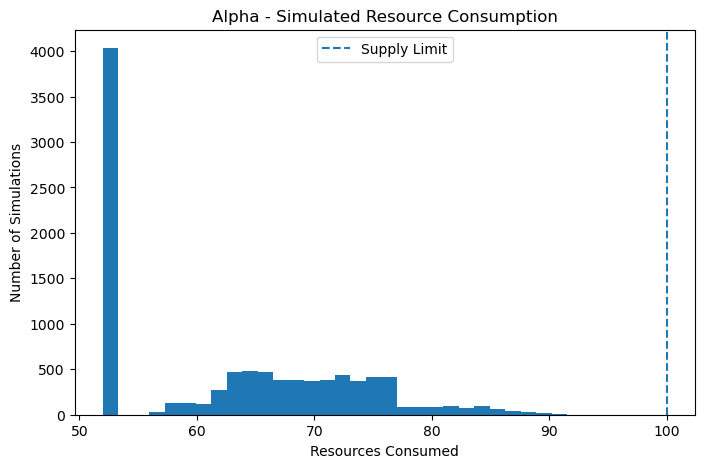

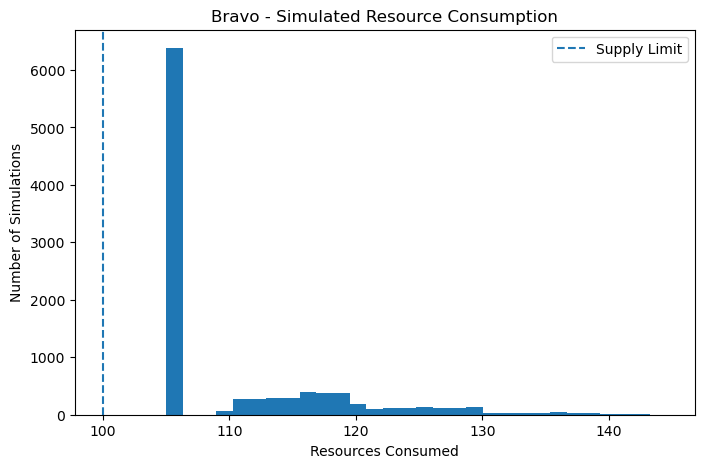

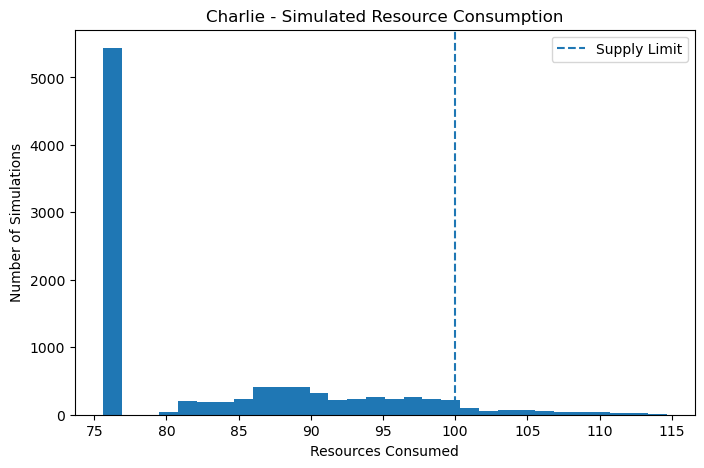

In [17]:
for name, data in simulation_results.items():
    resources = data['resources_consumed']
    supply_limit = routes[name]['supply_level']

    plot_resource_distribution(resources, name, supply_limit)

### Travel Time Distributions

Travel time is also affected by uncertain equipment failures and threat encounters.

The following histograms illustrate how these events can increase travel time beyond the deterministic baseline. The distributions help identify the variability and potential delays associated with each route.

In [19]:
def plot_travel_time_distribution(travel_times, route_name):
    plt.figure(figsize=(8,5))
    plt.hist(travel_times, bins=30)
    plt.xlabel('Travel Time (hours)')
    plt.ylabel('Number of Simulations')
    plt.title(f'{route_name} - Simulated Travel Time')
    plt.show()

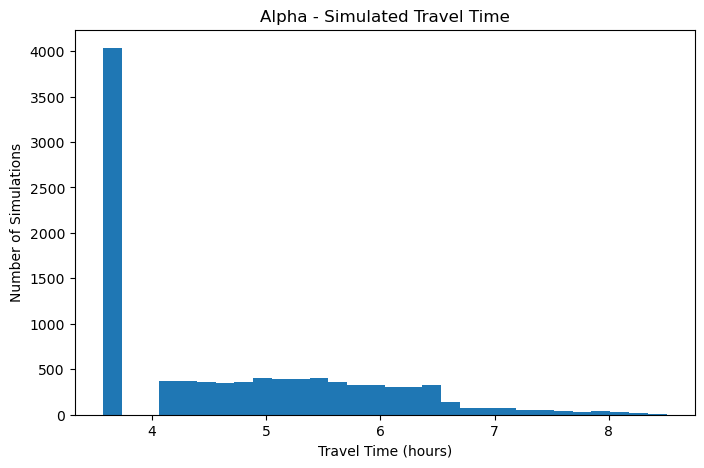

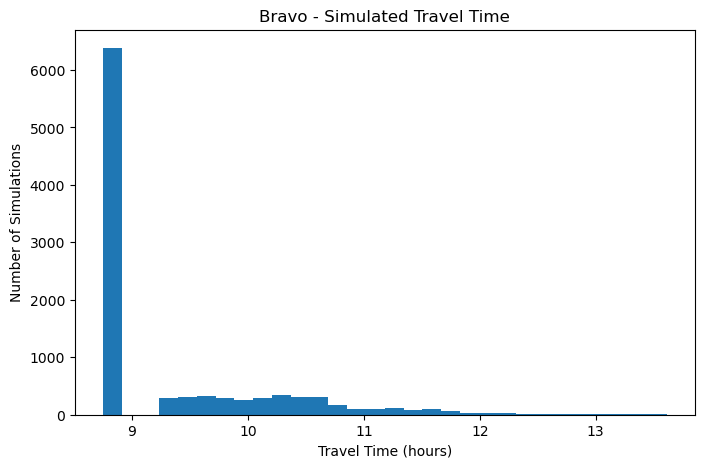

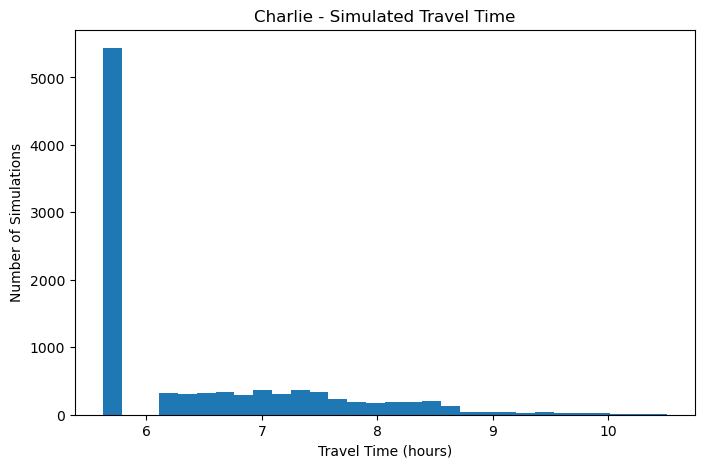

In [20]:
for name, data in simulation_results.items():
    travel_times = data['travel_times']
    plot_travel_time_distribution(travel_times, name)

### Distribution Analysis Summary

The simulated distributions reveal differences that are not fully captured by average values.

Alpha has the lowest travel times and resource consumption, with no resource-related failures observed across 10,000 simulations.

Bravo exceeds the available supply even under baseline conditions, making it infeasible under the current assumptions.

Charlie generally remains within the supply limit, but its upper tail extends beyond the available resources, producing a small proportion of unsuccessful outcomes.

These results demonstrate the importance of examining variability and tail outcomes when comparing alternatives under uncertainty.

## Multi-Criteria Decision Analysis

The Monte Carlo simulation provides estimates of mission success, travel time, resource consumption, and threat exposure. These estimates are used to compare the available routes.

A two-stage decision process is applied:

1. **Feasibility screening:** Routes must achieve a simulated success rate of at least 90% to remain under consideration.
2. **Weighted evaluation:** Eligible routes are compared using normalized failure risk, expected travel time, resource consumption, and threat exposure.

The 90% threshold and criterion weights are illustrative modelling assumptions rather than operational standards.

In [23]:
minimum_success_rate = 0.90
viable_routes = {}
for name, data in simulation_results.items():
    success_rate = data['success_count'] / num_simulations
    if success_rate >= minimum_success_rate:
        viable_routes[name] = data

print('Routes meeting the minimum success threshold:')

for name in viable_routes:
    print(f'    {name}')

Routes meeting the minimum success threshold:
    Alpha
    Charlie


In [24]:
max_acceptable_time = 10
max_available_resources = 100
max_acceptable_failure_rate = 1 - minimum_success_rate

failure_weight = 0.40
time_weight = 0.20
resource_weight = 0.20
threat_weight = 0.20

for name, data in viable_routes.items():
    success_rate = data['success_count'] / num_simulations
    failure_rate = 1 - success_rate

    average_travel_time = data['total_travel_time'] / num_simulations
    average_resources_consumed = data['total_resources_consumed'] / num_simulations

    threat_rate = data['threat_count'] / num_simulations

    normalized_failure = failure_rate / max_acceptable_failure_rate
    normalized_time = average_travel_time / max_acceptable_time
    normalized_resources = average_resources_consumed / max_available_resources

    coa_cost = (
        failure_weight * normalized_failure
        + time_weight * normalized_time
        + resource_weight * normalized_resources
        + threat_weight * threat_rate
    )

    data['coa_cost'] = coa_cost

    print(name)
    print(f'    Normalized failure: {normalized_failure:.3f}')
    print(f'    Normalized time: {normalized_time:.3f}')
    print(f'    Normalized resources: {normalized_resources:.3f}')
    print(f'    Threat exposure: {threat_rate:.3f}')
    print(f'    COA cost: {coa_cost:.3f}')

Alpha
    Normalized failure: 0.000
    Normalized time: 0.470
    Normalized resources: 0.628
    Threat exposure: 0.501
    COA cost: 0.320
Charlie
    Normalized failure: 0.581
    Normalized time: 0.643
    Normalized resources: 0.831
    Threat exposure: 0.304
    COA cost: 0.588


In [25]:
best_route = None
best_cost = float('inf')

for name, data in viable_routes.items():
    if data['coa_cost'] < best_cost:
        best_route = name
        best_cost = data['coa_cost']

print(f'Recommended COA: {best_route}')
print(f'COA cost: {best_cost:.3f}')

Recommended COA: Alpha
COA cost: 0.320


## Sensitivity Analysis

The weighted decision model recommends Alpha under the baseline criterion weights. However, the recommendation depends on how much importance is assigned to each evaluation criterion.

To examine this dependence, the weight assigned to threat exposure is varied from 0% to 100%.

As the threat weight increases, the remaining weight is distributed among failure risk, travel time, and resource consumption in the same relative proportions as the baseline model (50:25:25).

This analysis identifies the point at which Charlie's lower threat exposure outweighs Alpha's advantages in the other criteria.

In [27]:
threat_weights = np.arange(0, 1.01, 0.01)
sensitivity_results = []

for threat_weight in threat_weights:
    remaining_weight = 1 - threat_weight
    failure_weight = 0.50 * remaining_weight
    time_weight = 0.25 * remaining_weight
    resource_weight = 0.25 * remaining_weight
    route_costs = {}
    for name, data in viable_routes.items():
        success_rate = data['success_count'] / num_simulations
        failure_rate = 1 - success_rate
        normalized_failure = failure_rate / max_acceptable_failure_rate
        average_travel_time = data['total_travel_time'] / num_simulations
        normalized_time = average_travel_time / max_acceptable_time
        average_resources_consumed = data['total_resources_consumed'] / num_simulations
        normalized_resources = average_resources_consumed / max_available_resources
        threat_rate = data['threat_count'] / num_simulations

        sensitivity_cost = (
            failure_weight * normalized_failure +
            time_weight * normalized_time +
            resource_weight * normalized_resources +
            threat_weight * threat_rate
        )
        route_costs[name] = sensitivity_cost

    sensitivity_results.append({
        'threat_weight': threat_weight,
        'Alpha': route_costs['Alpha'],
        'Charlie': route_costs['Charlie']
    })
print(sensitivity_results[0])
print(sensitivity_results[20])
print(sensitivity_results[-1])


{'threat_weight': 0.0, 'Alpha': 0.2743222799444139, 'Charlie': 0.6590013691562185}
{'threat_weight': 0.2, 'Alpha': 0.31969782395553115, 'Charlie': 0.5881010953249748}
{'threat_weight': 1.0, 'Alpha': 0.5012, 'Charlie': 0.3045}


In [28]:
threat_weights_plot = []
alpha_costs = []
charlie_costs = []

for result in sensitivity_results:
    threat_weights_plot.append(result['threat_weight'])
    alpha_costs.append(result['Alpha'])
    charlie_costs.append(result['Charlie'])

In [29]:
alpha_base = sensitivity_results[0]['Alpha']
charlie_base = sensitivity_results[0]['Charlie']

alpha_threat = sensitivity_results[-1]['Alpha']
charlie_threat = sensitivity_results[-1]['Charlie']

crossover_weight = (
    (charlie_base - alpha_base)
    / ((alpha_threat - alpha_base) - (charlie_threat - charlie_base))
)

print(f'Crossover threat weight: {crossover_weight:.2%}')

Crossover threat weight: 66.17%


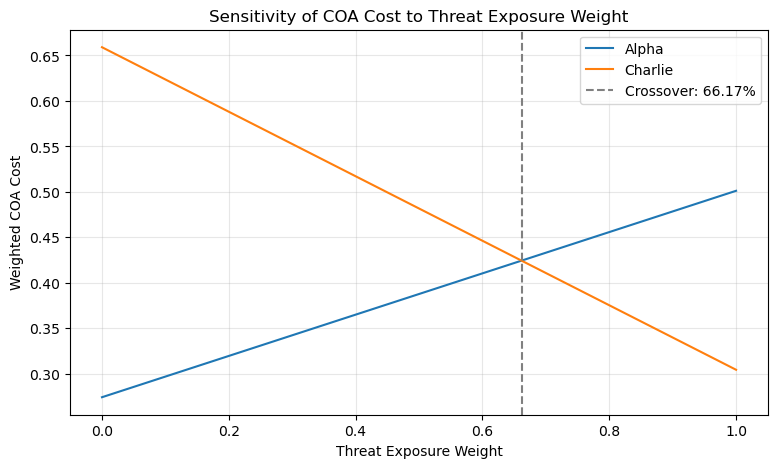

In [30]:
plt.figure(figsize=(9,5))
plt.plot(threat_weights_plot, alpha_costs, label='Alpha')
plt.plot(threat_weights_plot, charlie_costs, label='Charlie')
plt.xlabel('Threat Exposure Weight')
plt.ylabel('Weighted COA Cost')
plt.title('Sensitivity of COA Cost to Threat Exposure Weight')
plt.axvline(
    crossover_weight,
    linestyle='--',
    color='gray',
    label=f'Crossover: {crossover_weight:.2%}'
)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Sensitivity Analysis Results

Under the baseline criterion weights, Alpha is the preferred route.

The sensitivity analysis identifies a crossover at approximately 66.17% threat exposure weight.

Below this threshold, Alpha's advantages in simulated mission success, travel time, and resource consumption outweigh Charlie's lower threat exposure.

Above this threshold, Charlie becomes preferable because threat exposure receives sufficient weight to outweigh Alpha's advantages in the other criteria.

This demonstrates that the recommended course of action depends on the decision-maker's priorities rather than being universally optimal.

The crossover is conditional on the fictional scenario parameters, simulation assumptions, and chosen evaluation criteria.

## Conclusion and Limitations

### Conclusion

The simulation evaluates three fictional routes using travel time, resource consumption, equipment reliability, and threat exposure.

Under the baseline decision weights, Alpha is the preferred route. Bravo fails to meet the minimum simulated success threshold, while Charlie remains viable but receives a higher weighted cost.

Sensitivity analysis shows that Charlie becomes preferable when the weight assigned to threat exposure exceeds approximately 66.17%.

The results illustrate how Monte Carlo simulation and multi-criteria decision analysis can support comparisons between alternatives under uncertainty.

### Limitations

- All scenario parameters are fictional and illustrative.
- Mission success is defined solely by whether resource consumption remains within the available supply.
- Equipment failures and threat encounters are represented using simplified probability models.
- The simulation does not capture every possible dependency between uncertain events.
- The evaluation weights and feasibility threshold are subjective modelling assumptions.
- Simulation estimates are not guarantees of future outcomes.

The recommended route is therefore conditional on the assumptions and priorities used in this model.